# Model Error Analysis

This notebook analyzes errors made by the existing ResNet-18 and EfficientNet-B0 checkpoints on the existing test split. It does not retrain models, alter data, create a split, or change preprocessing.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from PIL import Image
from torch import nn
from torchvision.models import efficientnet_b0, resnet18

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RESULTS_DIR = PROJECT_ROOT / 'results'
MODELS_DIR = PROJECT_ROOT / 'models'
IMAGE_DIR = PROJECT_ROOT.parent / 'Dataset'
TEST_MANIFEST = RESULTS_DIR / 'test.csv'
CLASS_MAPPING = RESULTS_DIR / 'class_to_index.json'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 32

import sys
sys.path.insert(0, str(PROJECT_ROOT))
from src.dataset import SorghumDataset, load_class_to_idx, make_loader
from src.preprocessing import get_test_transform

print(f'Project root: {PROJECT_ROOT}')
print(f'Device: {DEVICE}')

Project root: c:\Users\nihar\OneDrive\Desktop\Water To Pixels\pixels-to-water
Device: cuda


In [2]:
class_to_idx = load_class_to_idx(CLASS_MAPPING)
idx_to_class = {index: cultivar for cultivar, index in class_to_idx.items()}
num_classes = len(class_to_idx)
test_manifest = pd.read_csv(TEST_MANIFEST)
if not set(test_manifest['cultivar']).issubset(class_to_idx):
    raise ValueError('Test manifest contains cultivars absent from the existing class mapping.')
test_dataset = SorghumDataset(test_manifest, IMAGE_DIR, get_test_transform(), class_to_idx)
test_loader = make_loader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
print(f'Loaded {len(test_dataset)} test images, {num_classes} classes, deterministic test preprocessing.')

Loaded 500 test images, 100 classes, deterministic test preprocessing.


In [3]:
def load_checkpoint_model(model_name, checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    checkpoint_num_classes = checkpoint.get('num_classes', num_classes)
    if checkpoint_num_classes != num_classes:
        raise ValueError(f'{model_name} checkpoint has {checkpoint_num_classes} classes, expected {num_classes}.')
    if model_name == 'ResNet-18':
        model = resnet18(weights=None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    else:
        model = efficientnet_b0(weights=None)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    model.load_state_dict(checkpoint['model_state_dict'])
    return model.to(DEVICE).eval()

def run_inference(model):
    rows = []
    with torch.no_grad():
        for batch_start, (images, labels) in enumerate(test_loader):
            probabilities = torch.softmax(model(images.to(DEVICE)), dim=1).cpu()
            confidence, predictions = probabilities.max(dim=1)
            for offset, (label, prediction, score) in enumerate(zip(labels, predictions, confidence)):
                row = test_manifest.iloc[batch_start * BATCH_SIZE + offset]
                rows.append({
                    'image': row['image'],
                    'true_cultivar': idx_to_class[int(label)],
                    'predicted_cultivar': idx_to_class[int(prediction)],
                    'confidence': float(score),
                    'correct': bool(label == prediction),
                })
    return pd.DataFrame(rows)

models = {
    'ResNet-18': load_checkpoint_model('ResNet-18', MODELS_DIR / 'resnet18_best.pth'),
    'EfficientNet-B0': load_checkpoint_model('EfficientNet-B0', MODELS_DIR / 'efficientnet_b0_best.pth'),
}
predictions = {name: run_inference(model) for name, model in models.items()}
for name, frame in predictions.items():
    print(f'{name}: {len(frame) - frame["correct"].sum()} errors of {len(frame)} test images')

ResNet-18: 157 errors of 500 test images
EfficientNet-B0: 129 errors of 500 test images


In [4]:
def confusion_table(frame):
    errors = frame.loc[~frame['correct'], ['true_cultivar', 'predicted_cultivar']]
    return (errors.value_counts().rename('Number of Errors').reset_index()
            .sort_values(['Number of Errors', 'true_cultivar', 'predicted_cultivar'], ascending=[False, True, True])
            .reset_index(drop=True))

confusion_tables = {name: confusion_table(frame) for name, frame in predictions.items()}
for name, table in confusion_tables.items():
    print(f'{name} confusion pairs')
    display(table.head(15))

ResNet-18 confusion pairs


,true_cultivar,predicted_cultivar,Number of Errors
0,PI_329299,PI_329301,3
1,PI_152967,PI_257599,2
2,PI_154844,PI_152860,2
3,PI_154844,PI_154944,2
4,PI_156178,PI_255239,2
5,PI_217691,PI_157035,2
6,PI_221548,PI_154846,2
7,PI_329300,PI_329301,2
8,PI_144134,PI_156268,1
9,PI_144134,PI_255239,1


EfficientNet-B0 confusion pairs


,true_cultivar,predicted_cultivar,Number of Errors
0,PI_152730,PI_146890,4
1,PI_152751,PI_152733,2
2,PI_221651,PI_157035,2
3,PI_276837,PI_253986,2
4,PI_329300,PI_329301,2
5,PI_144134,PI_145626,1
6,PI_144134,PI_196586,1
7,PI_145619,PI_145633,1
8,PI_145619,PI_329333,1
9,PI_145626,PI_144134,1


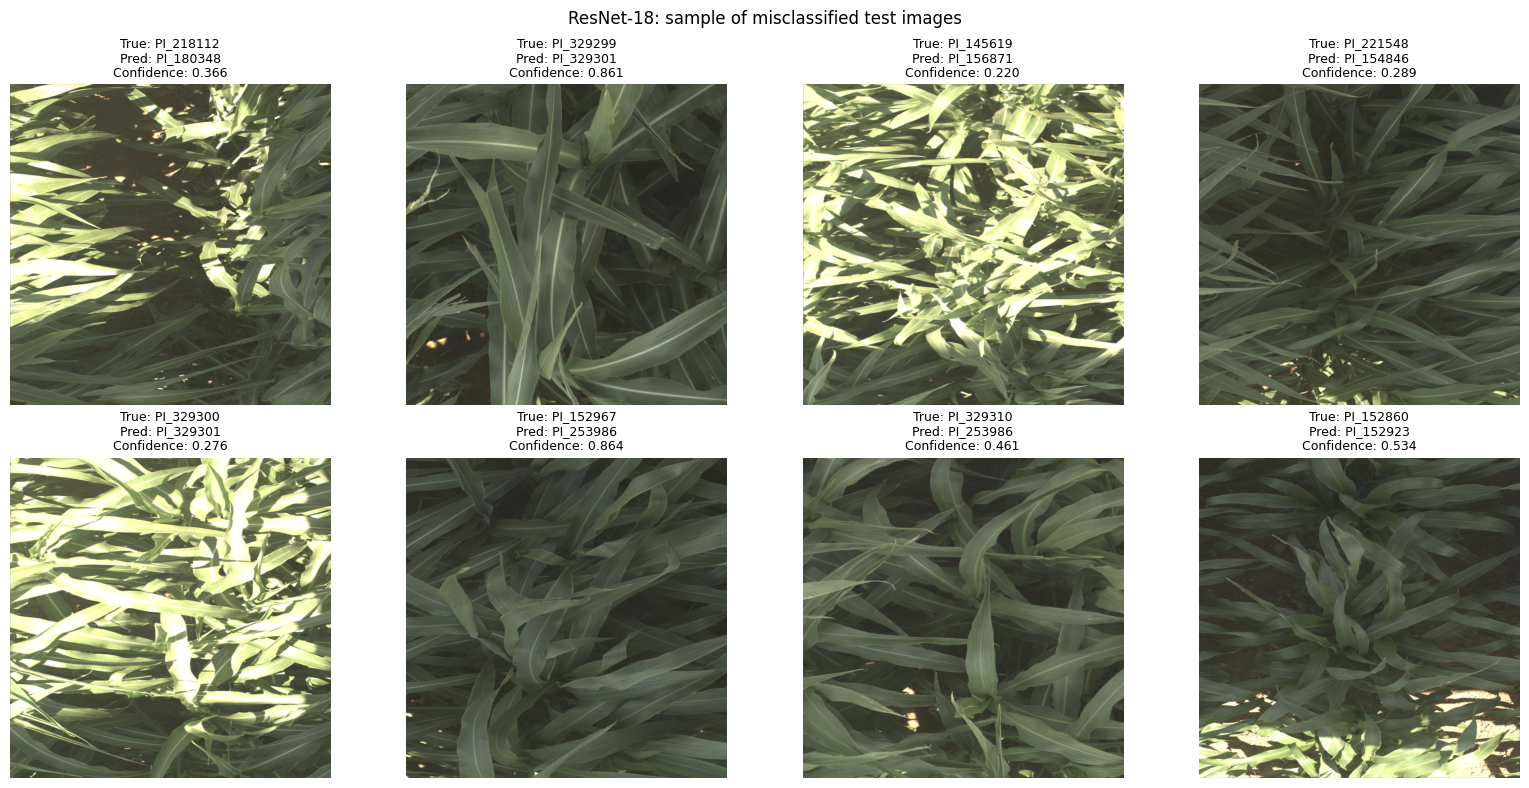

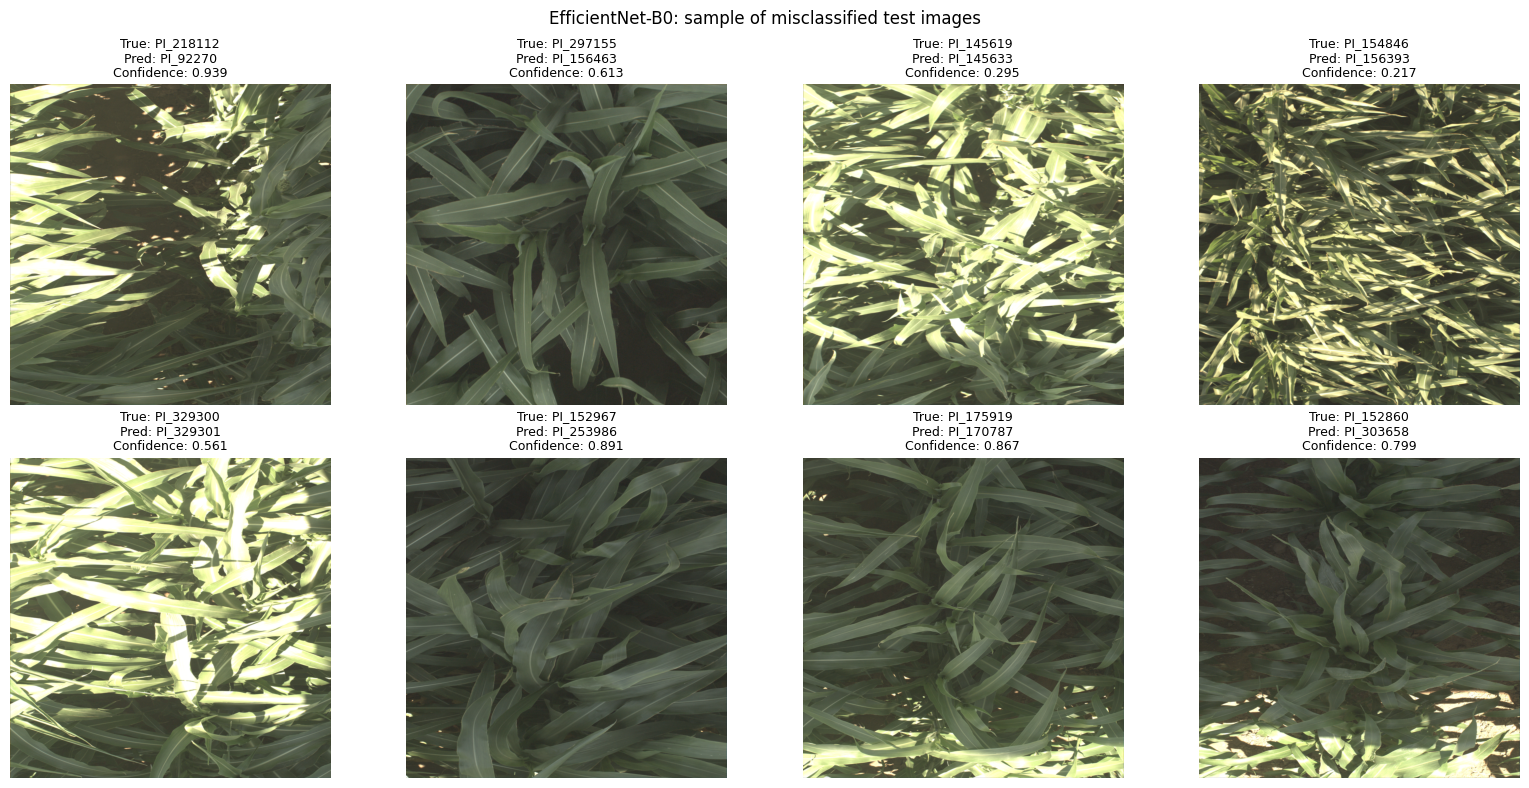

In [5]:
def show_misclassified_examples(name, frame, count=8):
    examples = frame.loc[~frame['correct']].head(count).reset_index(drop=True)
    columns = 4
    rows = (len(examples) + columns - 1) // columns
    figure, axes = plt.subplots(rows, columns, figsize=(16, 4 * rows))
    axes = list(axes.flat) if hasattr(axes, 'flat') else [axes]
    for axis, (_, example) in zip(axes, examples.iterrows()):
        image = Image.open(IMAGE_DIR / example['image']).convert('RGB')
        axis.imshow(image)
        axis.set_title(f"True: {example['true_cultivar']}\nPred: {example['predicted_cultivar']}\nConfidence: {example['confidence']:.3f}", fontsize=9)
        axis.axis('off')
    for axis in axes[len(examples):]:
        axis.axis('off')
    figure.suptitle(f'{name}: sample of misclassified test images')
    figure.tight_layout()
    plt.show()

for model_name, frame in predictions.items():
    show_misclassified_examples(model_name, frame)

In [8]:
error_counts = pd.Series({name: int((~frame['correct']).sum()) for name, frame in predictions.items()}, name='Number of Errors')
print('Error-count comparison')
display(error_counts.to_frame())

resnet_pairs = set(map(tuple, confusion_tables['ResNet-18'][['true_cultivar', 'predicted_cultivar']].values))
efficientnet_pairs = set(map(tuple, confusion_tables['EfficientNet-B0'][['true_cultivar', 'predicted_cultivar']].values))
shared_pairs = sorted(resnet_pairs & efficientnet_pairs)
shared_pair_table = pd.DataFrame(shared_pairs, columns=['True Cultivar', 'Predicted Cultivar'])
if shared_pairs:
    resnet_pair_counts = confusion_tables['ResNet-18'].set_index(['true_cultivar', 'predicted_cultivar'])['Number of Errors']
    efficientnet_pair_counts = confusion_tables['EfficientNet-B0'].set_index(['true_cultivar', 'predicted_cultivar'])['Number of Errors']
    shared_pair_table['ResNet-18 Errors'] = [int(resnet_pair_counts.loc[pair]) for pair in shared_pairs]
    shared_pair_table['EfficientNet-B0 Errors'] = [int(efficientnet_pair_counts.loc[pair]) for pair in shared_pairs]
print(f'Shared directed confusion pairs: {len(shared_pairs)}')
display(shared_pair_table.head(15))

per_cultivar = pd.DataFrame({
    name: frame.groupby('true_cultivar')['correct'].apply(lambda values: int((~values).sum()))
    for name, frame in predictions.items()
}).rename_axis('True Cultivar').reset_index()
per_cultivar['Better model'] = per_cultivar.apply(lambda row: 'ResNet-18' if row['ResNet-18'] < row['EfficientNet-B0'] else ('EfficientNet-B0' if row['EfficientNet-B0'] < row['ResNet-18'] else 'Equal'), axis=1)
print('Cultivars with different error counts')
display(per_cultivar.loc[per_cultivar['ResNet-18'] != per_cultivar['EfficientNet-B0']].sort_values(['ResNet-18', 'EfficientNet-B0']))

model_win_counts = per_cultivar['Better model'].value_counts().reindex(['ResNet-18', 'EfficientNet-B0', 'Equal'], fill_value=0)
print(f"Cultivar-level results: ResNet-18 better on {model_win_counts['ResNet-18']}, EfficientNet-B0 better on {model_win_counts['EfficientNet-B0']}, equal on {model_win_counts['Equal']}.")
print('Top five directed confusion pairs per model:')
for model_name, table in confusion_tables.items():
    top_pairs = table.head(5).copy()
    top_pairs['pair'] = top_pairs['true_cultivar'] + ' -> ' + top_pairs['predicted_cultivar']
    print(model_name)
    display(top_pairs[['pair', 'Number of Errors']])

Error-count comparison


,Number of Errors
ResNet-18,157
EfficientNet-B0,129


Shared directed confusion pairs: 28


,True Cultivar,Predicted Cultivar,ResNet-18 Errors,EfficientNet-B0 Errors
0,PI_145626,PI_255239,1,1
1,PI_152591,PI_156326,1,1
2,PI_152730,PI_146890,1,4
3,PI_152733,PI_154987,1,1
4,PI_152751,PI_152733,1,2
5,PI_152967,PI_253986,1,1
6,PI_154846,PI_155516,1,1
7,PI_154987,PI_229841,1,1
8,PI_156178,PI_255239,2,1
9,PI_156326,PI_152862,1,1


Cultivars with different error counts


,True Cultivar,ResNet-18,EfficientNet-B0,Better model
74,PI_257600,0,1,ResNet-18
85,PI_329256,0,1,ResNet-18
91,PI_329319,0,1,ResNet-18
52,PI_180348,0,2,ResNet-18
56,PI_196049,0,2,ResNet-18
...,...,...,...,...
40,PI_156463,4,1,EfficientNet-B0
37,PI_156326,4,2,EfficientNet-B0
84,PI_303658,4,2,EfficientNet-B0
88,PI_329300,4,3,EfficientNet-B0


Cultivar-level results: ResNet-18 better on 24, EfficientNet-B0 better on 37, equal on 39.
Top five directed confusion pairs per model:
ResNet-18


,pair,Number of Errors
0,PI_329299 -> PI_329301,3
1,PI_152967 -> PI_257599,2
2,PI_154844 -> PI_152860,2
3,PI_154844 -> PI_154944,2
4,PI_156178 -> PI_255239,2


EfficientNet-B0


,pair,Number of Errors
0,PI_152730 -> PI_146890,4
1,PI_152751 -> PI_152733,2
2,PI_221651 -> PI_157035,2
3,PI_276837 -> PI_253986,2
4,PI_329300 -> PI_329301,2


In [9]:
summary_rows = []
for model_name, table in confusion_tables.items():
    for _, row in table.iterrows():
        summary_rows.append({
            'model': model_name,
            'true_cultivar': row['true_cultivar'],
            'predicted_cultivar': row['predicted_cultivar'],
            'number_of_errors': int(row['Number of Errors']),
        })
error_summary = pd.DataFrame(summary_rows, columns=['model', 'true_cultivar', 'predicted_cultivar', 'number_of_errors'])
ERROR_SUMMARY_PATH = RESULTS_DIR / 'error_analysis_summary.csv'
error_summary.to_csv(ERROR_SUMMARY_PATH, index=False)
print(f'Saved {len(error_summary)} observed confusion rows to {ERROR_SUMMARY_PATH}.')
display(error_summary.head(20))

Saved 270 observed confusion rows to c:\Users\nihar\OneDrive\Desktop\Water To Pixels\pixels-to-water\results\error_analysis_summary.csv.


,model,true_cultivar,predicted_cultivar,number_of_errors
0,ResNet-18,PI_329299,PI_329301,3
1,ResNet-18,PI_152967,PI_257599,2
2,ResNet-18,PI_154844,PI_152860,2
3,ResNet-18,PI_154844,PI_154944,2
4,ResNet-18,PI_156178,PI_255239,2
5,ResNet-18,PI_217691,PI_157035,2
6,ResNet-18,PI_221548,PI_154846,2
7,ResNet-18,PI_329300,PI_329301,2
8,ResNet-18,PI_144134,PI_156268,1
9,ResNet-18,PI_144134,PI_255239,1


## Findings

These findings are based only on the actual predictions generated above for the 500-image existing test split.

- ResNet-18 made 157 errors; EfficientNet-B0 made 129 errors. EfficientNet-B0 therefore made 28 fewer misclassifications.
- The most frequent ResNet-18 directed confusion was `PI_329299 -> PI_329301` with 3 errors. Its next most frequent pairs each had 2 errors: `PI_152967 -> PI_257599`, `PI_154844 -> PI_152860`, `PI_154844 -> PI_154944`, and `PI_156178 -> PI_255239`.
- The most frequent EfficientNet-B0 directed confusion was `PI_152730 -> PI_146890` with 4 errors. Four further pairs had 2 errors each: `PI_152751 -> PI_152733`, `PI_221651 -> PI_157035`, `PI_276837 -> PI_253986`, and `PI_329300 -> PI_329301`.
- The models shared 28 directed confusion pairs, so some mistakes were similar, but the full error sets were not identical.
- At the cultivar level, ResNet-18 had fewer errors for 24 cultivars, EfficientNet-B0 had fewer errors for 37 cultivars, and the models were tied for 39 cultivars.
- The displayed image grids provide examples with true cultivar, predicted cultivar, and confidence. They do not establish a visual cause for any error.